# 🎨 Procesamiento de Imágenes con IA — Clase 4: Laboratorio de Espacios de Color

**Politécnico Malvinas Argentinas** | Tecnicatura en Cs de Datos e IA | 2026  
**Materia:** Procesamiento de Imágenes con IA  
**Tipo:** Clase Práctica — Laboratorio de Demostración (Clase 4, Semana 2)  
**Tema:** Píxeles · Resolución · Espacios de Color (RGB, HSV, CMYK, LAB) · Conversiones  
**Duración estimada:** 90 minutos

---
> **¿Cómo usar este notebook?**  
> Ejecutá cada celda en orden con `Shift + Enter`.  
> Las celdas marcadas con `# TODO:` son las que tenés que completar vos.  
> Las celdas de **Demostración** ya están resueltas — corré, analizá y entendé el código.

## 🎯 Objetivos de Aprendizaje

| # | Objetivo | Nivel Bloom |
|---|----------|-------------|
| 1 | **Analizar** una imagen digital como matriz numpy e interpretar sus dimensiones (H, W, C) | Analizar |
| 2 | **Separar y visualizar** los canales individuales de una imagen RGB | Aplicar |
| 3 | **Comparar** la representación de un mismo color en los espacios RGB, HSV y LAB | Evaluar |
| 4 | **Implementar** conversiones entre espacios de color usando OpenCV y Pillow | Aplicar |
| 5 | **Aplicar** segmentación por color usando `cv2.inRange()` sobre espacio HSV | Aplicar |
| 6 | **Analizar** el impacto del formato de archivo (JPEG vs PNG) en la calidad y tamaño | Analizar |

## 📌 Conexión con la Clase 3 (Teórica)

En la Clase 3 vimos que:

```
Imagen digital = array numpy de forma (H, W, C)
Píxel RGB      = 3 valores [R, G, B] de 0 a 255
Espacios clave: RGB (pantallas) | HSV (segmentación) | CMYK (impresión) | LAB (percepción)
```

En este laboratorio **vamos a experimentar con todos esos conceptos** directamente en código.  
Al final vas a poder responder: ¿por qué HSV es mejor que RGB para detectar colores?


---
## ⚙️ Paso 0 — Setup del Entorno

Verificamos dependencias e importamos todo lo necesario para esta clase.

In [2]:
# En Colab las librerías ya están instaladas.
# Si trabajás en local, descomentá la siguiente línea:
# %pip install Pillow opencv-python-headless scikit-image

from PIL import Image, ImageFilter
import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from skimage import data
import os

# Configuración de visualización
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10

# Verificar versiones
from PIL import __version__ as pil_ver
print(f'Pillow:  {pil_ver}')
print(f'OpenCV:  {cv2.__version__}')
print(f'numpy:   {np.__version__}')
print('✅ Entorno listo')

Pillow:  11.3.0
OpenCV:  5.0.0
numpy:   2.0.2
✅ Entorno listo


---
## 🖼️ Paso 1 — Cargar Imágenes de Trabajo

Usamos imágenes de `skimage.data` para no depender de archivos externos.  
Estas imágenes son ideales para explorar espacios de color por su variedad cromática.

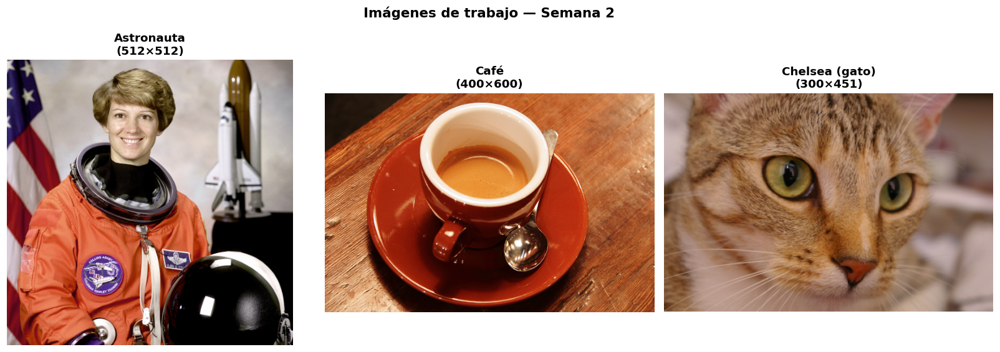


Información de las imágenes:
  Astronauta: shape=(512, 512, 3), dtype=uint8, min=0, max=255, memoria=768.0 KB
  Café: shape=(400, 600, 3), dtype=uint8, min=0, max=255, memoria=703.1 KB
  Gato: shape=(300, 451, 3), dtype=uint8, min=0, max=231, memoria=396.4 KB


In [3]:
# ─── Cargar imágenes de muestra ───────────────────────────────────────────────
img_astronaut = data.astronaut()   # (512, 512, 3) RGB — astronauta, colores variados
img_coffee    = data.coffee()      # (400, 600, 3) RGB — taza, tonos cálidos dominantes
img_cat       = data.chelsea()     # (300, 451, 3) RGB — gato naranja, ideal para segmentación

# Mostrar las tres imágenes
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
imagenes = [
    (img_astronaut, 'Astronauta\n(512×512)'),
    (img_coffee,    'Café\n(400×600)'),
    (img_cat,       'Chelsea (gato)\n(300×451)'),
]
for ax, (img, title) in zip(axes, imagenes):
    ax.imshow(img)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel(f'shape: {img.shape} | dtype: {img.dtype}')
    ax.axis('off')

plt.suptitle('Imágenes de trabajo — Semana 2', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print('\nInformación de las imágenes:')
for nombre, img in [('Astronauta', img_astronaut), ('Café', img_coffee), ('Gato', img_cat)]:
    print(f'  {nombre}: shape={img.shape}, dtype={img.dtype}, '
          f'min={img.min()}, max={img.max()}, '
          f'memoria={img.nbytes/1024:.1f} KB')

---
## 🔴🟢🔵 Paso 2 — Los Canales RGB

### 2.1 Demostración: Separar y visualizar canales

Cada imagen RGB es, en realidad, la **superposición de tres imágenes** (tres matrices 2D).  
Separarlas nos permite analizar qué información aporta cada canal.

Imagen original: (512, 512, 3)
Canal R: (512, 512) | media: 141.6 | max: 255
Canal G: (512, 512) | media: 105.8 | max: 255
Canal B: (512, 512) | media: 96.5 | max: 255


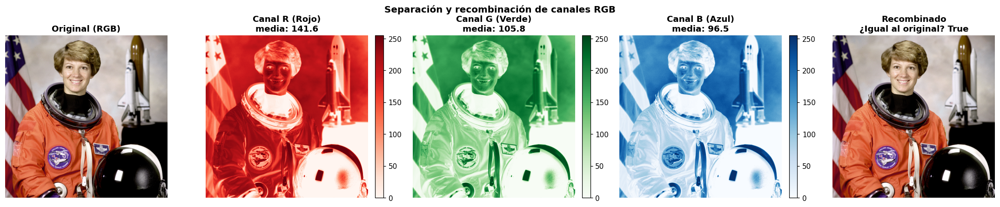

In [4]:
# ─── Separar canales RGB ──────────────────────────────────────────────────────
img = img_astronaut

R = img[:, :, 0]   # Canal Rojo  — forma: (512, 512)
G = img[:, :, 1]   # Canal Verde — forma: (512, 512)
B = img[:, :, 2]   # Canal Azul  — forma: (512, 512)

print(f'Imagen original: {img.shape}')
print(f'Canal R: {R.shape} | media: {R.mean():.1f} | max: {R.max()}')
print(f'Canal G: {G.shape} | media: {G.mean():.1f} | max: {G.max()}')
print(f'Canal B: {B.shape} | media: {B.mean():.1f} | max: {B.max()}')

# ─── Visualización ───────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 5, figsize=(20, 4))

# Original
axes[0].imshow(img)
axes[0].set_title('Original (RGB)', fontweight='bold')

# Canales individuales con colormap temático
config = [
    (R, 'Canal R (Rojo)',  'Reds',   R.mean()),
    (G, 'Canal G (Verde)', 'Greens', G.mean()),
    (B, 'Canal B (Azul)',  'Blues',  B.mean()),
    # Versión recombinada para demostrar que es lo mismo
]
for ax, (canal, titulo, cmap, media) in zip(axes[1:4], config):
    im = ax.imshow(canal, cmap=cmap)
    ax.set_title(f'{titulo}\nmedia: {media:.1f}', fontweight='bold')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

# Recombinar para verificar que es idéntico al original
img_recombinado = np.stack([R, G, B], axis=2)   # volver a unir los 3 canales
axes[4].imshow(img_recombinado)
axes[4].set_title(f'Recombinado\n¿Igual al original? {np.array_equal(img, img_recombinado)}',
                  fontweight='bold')

for ax in axes:
    ax.axis('off')

plt.suptitle('Separación y recombinación de canales RGB', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### 2.2 ✏️ Actividad Guiada — Canales del Café

La imagen `data.coffee()` tiene **tonos cálidos dominantes** (rojos y amarillos).  
Antes de ejecutar: **¿qué canal esperás que tenga la media más alta? ¿R, G o B?**

Escribí tu predicción acá antes de ejecutar:  
**Mi predicción:** ...

Estadísticas de canales de data.coffee():
Canal R: media = 158.6
Canal G: media = 85.8
Canal B: media = 51.5


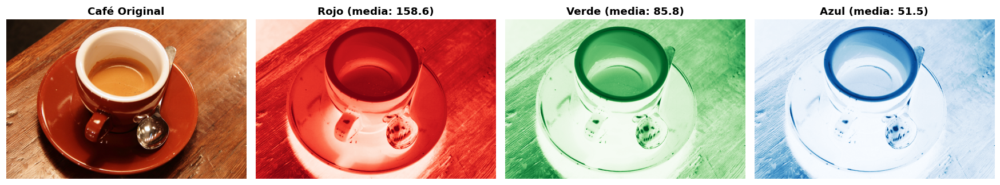

In [5]:
# TODO 2.1 — Separar canales de la imagen de café y mostrar estadísticas
R_coffee = img_coffee[:, :, 0]
G_coffee = img_coffee[:, :, 1]
B_coffee = img_coffee[:, :, 2]

print("Estadísticas de canales de data.coffee():")
print(f"Canal R: media = {R_coffee.mean():.1f}")
print(f"Canal G: media = {G_coffee.mean():.1f}")
print(f"Canal B: media = {B_coffee.mean():.1f}")

# TODO 2.2 — Visualizar la imagen y sus 3 canales (fig con 4 subplots)
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(img_coffee)
axes[0].set_title('Café Original', fontweight='bold')

axes[1].imshow(R_coffee, cmap='Reds')
axes[1].set_title(f'Rojo (media: {R_coffee.mean():.1f})', fontweight='bold')

axes[2].imshow(G_coffee, cmap='Greens')
axes[2].set_title(f'Verde (media: {G_coffee.mean():.1f})', fontweight='bold')

axes[3].imshow(B_coffee, cmap='Blues')
axes[3].set_title(f'Azul (media: {B_coffee.mean():.1f})', fontweight='bold')

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()

**Reflexión (doble click para editar):**

¿Qué canal tiene mayor media? ¿Coincidió con tu predicción? ¿Por qué tiene sentido para una imagen de café?

*Tu respuesta:*
El canal con mayor media es el Rojo (R). Esto coincide con mi predicción porque la imagen del café tiene una fuerte dominancia de tonos cálidos (marrones, rojizos y amarillentos de la madera, los granos y la taza), los cuales tienen un alto componente de rojo en la mezcla RGB.

---
## ✏️ Paso 3 — Manipulación Directa de Píxeles

### 3.1 Demostración: Leer, modificar y pintar píxeles

Recordar:
```
img[fila, columna]        → un píxel completo: array([R, G, B])
img[fila, columna, canal] → un valor único (0–255)
img[f1:f2, c1:c2]         → región de interés (ROI)
```

Píxel en (100, 200): [81 57 17]
  Solo canal R:      81
  Solo canal G:      57
  Solo canal B:      17


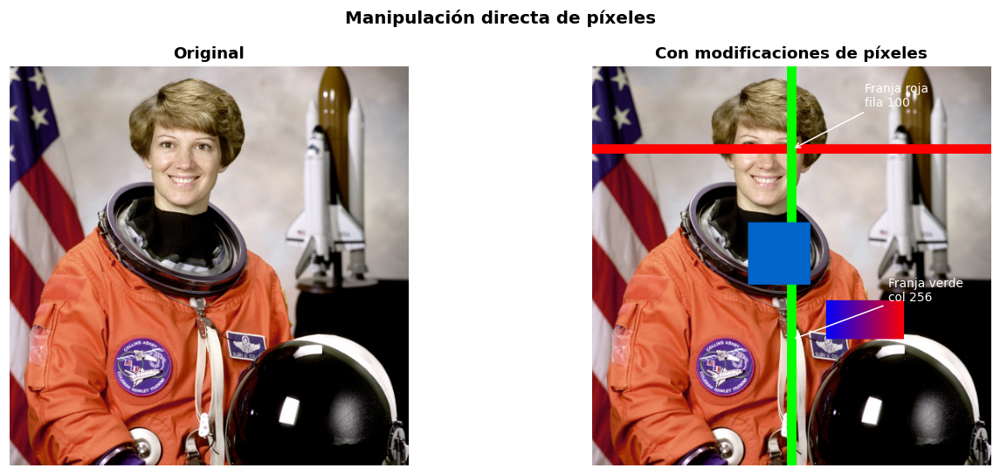

In [6]:
# ─── Lectura y modificación de píxeles ───────────────────────────────────────
img = img_astronaut.copy()   # ¡Siempre trabajar con copia!

# 1. Leer un píxel específico
pixel_100_200 = img[100, 200]     # fila=100, columna=200 → [R, G, B]
print(f'Píxel en (100, 200): {pixel_100_200}')
print(f'  Solo canal R:      {img[100, 200, 0]}')
print(f'  Solo canal G:      {img[100, 200, 1]}')
print(f'  Solo canal B:      {img[100, 200, 2]}')

# 2. Dibujar una franja roja horizontal
img[100:112, :] = [255, 0, 0]   # todas las columnas, filas 100–112 → rojo puro

# 3. Dibujar una franja verde vertical
img[:, 250:262] = [0, 255, 0]   # todas las filas, columnas 250–262 → verde puro

# 4. Crear un cuadrado azul (ROI)
img[200:280, 200:280] = [0, 100, 200]   # azul oscuro

# 5. Crear un degradado manual en una región
for col in range(300, 400):
    valor = int((col - 300) / 100 * 255)   # 0 → 255 a medida que avanza la columna
    img[300:350, col] = [valor, 0, 255 - valor]

# Mostrar resultado
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].imshow(img_astronaut)
axes[0].set_title('Original', fontweight='bold')
axes[0].axis('off')

axes[1].imshow(img)
axes[1].set_title('Con modificaciones de píxeles', fontweight='bold')
axes[1].axis('off')

# Anotar qué se modificó
from matplotlib.patches import FancyArrowPatch
axes[1].annotate('Franja roja\nfila 100', xy=(256, 106), xytext=(350, 50),
                 arrowprops=dict(arrowstyle='->', color='white'), color='white', fontsize=9)
axes[1].annotate('Franja verde\ncol 256', xy=(256, 350), xytext=(380, 300),
                 arrowprops=dict(arrowstyle='->', color='white'), color='white', fontsize=9)

plt.suptitle('Manipulación directa de píxeles', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### 3.2 ✏️ Actividad Guiada — Tu propio patrón de píxeles

Creá una imagen de 200×200 píxeles completamente negra y dibujá en ella:
1. Un cuadrado blanco en el centro (50×50 px)
2. Cuatro franjas de colores (una en cada borde)
3. Una diagonal de píxeles amarillos

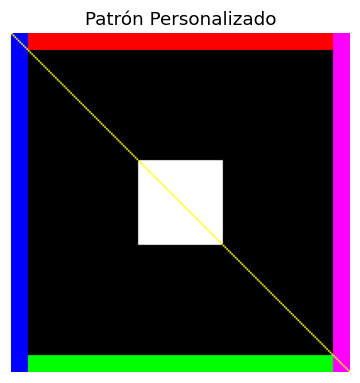

In [7]:
# TODO 3 — Crear imagen 200×200 y dibujar el patrón indicado
# Pista: np.zeros((200, 200, 3), dtype=np.uint8)  → imagen negra
# Pista: img_nueva[y1:y2, x1:x2] = [R, G, B]     → rellenar una región
# Pista: for i in range(200): img[i, i] = ...     → diagonal


# 1. Crear imagen negra de 200x200 píxeles
img_patron = np.zeros((200, 200, 3), dtype=np.uint8)

# 2. Dibujar franjas de colores en los bordes (10 px de grosor)
img_patron[0:10, :] = [255, 0, 0]      # Arriba: Rojo
img_patron[-10:, :] = [0, 255, 0]      # Abajo: Verde
img_patron[:, 0:10] = [0, 0, 255]      # Izquierda: Azul
img_patron[:, -10:] = [255, 0, 255]    # Derecha: Magenta

# 3. Dibujar cuadrado blanco en el centro (50x50 px)
# El centro de 200 es 100. Un cuadrado de 50px va de 75 a 125.
img_patron[75:125, 75:125] = [255, 255, 255]

# 4. Dibujar una diagonal de píxeles amarillos
for i in range(200):
    img_patron[i, i] = [255, 255, 0]

# Visualizar
plt.figure(figsize=(4, 4))
plt.imshow(img_patron)
plt.title("Patrón Personalizado")
plt.axis('off')
plt.show()



---
## 🟠 Paso 4 — Espacio de Color HSV

### 4.1 Demostración: Convertir y visualizar canales HSV

**¿Por qué HSV?**  
En RGB, el mismo color naranja puede tener cientos de combinaciones `[R, G, B]` según la iluminación.  
En HSV, ese naranja **siempre tiene Hue ≈ 10–25°**, sin importar cuán brillante o oscuro esté.

=== Estadísticas de canales HSV ===
H (Hue):       min=  0  max=179  media=13.5
S (Saturation):min=  0  max=255  media=110.1
V (Value):     min=  4  max=231  media=147.7


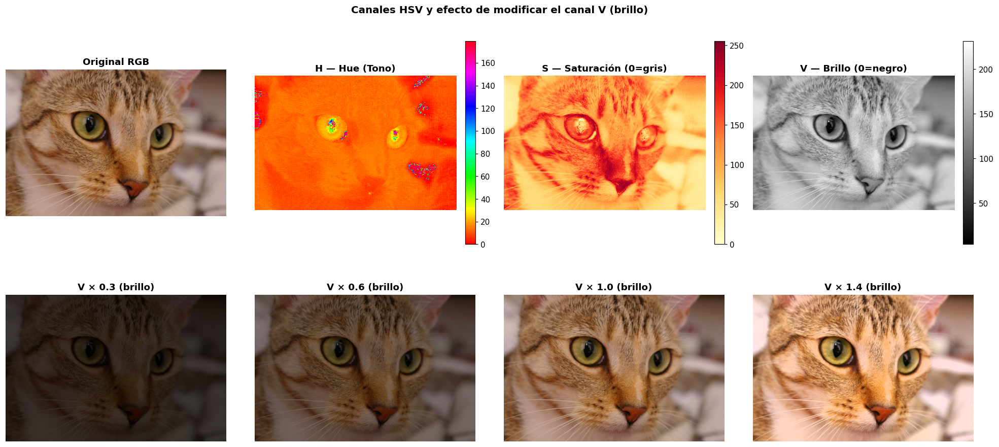

In [8]:
# ─── Conversión BGR → HSV ────────────────────────────────────────────────────
# IMPORTANTE: cv2 trabaja en BGR, no en RGB
# Como img_cat ya está en RGB (skimage), primero convertimos a BGR, luego a HSV
img_rgb = img_cat                                               # RGB original
img_bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)             # RGB → BGR (para OpenCV)
img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)             # BGR → HSV

H = img_hsv[:, :, 0]   # Hue: 0–179 en OpenCV (representa 0°–360°)
S = img_hsv[:, :, 1]   # Saturation: 0–255
V = img_hsv[:, :, 2]   # Value (brillo): 0–255

print('=== Estadísticas de canales HSV ===')
print(f'H (Hue):       min={H.min():3d}  max={H.max():3d}  media={H.mean():.1f}')
print(f'S (Saturation):min={S.min():3d}  max={S.max():3d}  media={S.mean():.1f}')
print(f'V (Value):     min={V.min():3d}  max={V.max():3d}  media={V.mean():.1f}')

# Visualización
fig, axes = plt.subplots(2, 4, figsize=(18, 9))

# Fila 1: Imagen original + canales HSV individuales
axes[0, 0].imshow(img_rgb)
axes[0, 0].set_title('Original RGB', fontweight='bold')

config_hsv = [
    (H, 'H — Hue (Tono)',              'hsv'),
    (S, 'S — Saturación (0=gris)',     'YlOrRd'),
    (V, 'V — Brillo (0=negro)',        'gray'),
]
for ax, (canal, titulo, cmap) in zip(axes[0, 1:], config_hsv):
    im = ax.imshow(canal, cmap=cmap)
    ax.set_title(titulo, fontweight='bold')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

# Fila 2: Efecto de modificar V (brillo) manualmente
for j, factor in enumerate([0.3, 0.6, 1.0, 1.4]):
    img_mod = img_hsv.copy().astype(np.float32)
    img_mod[:, :, 2] = np.clip(img_mod[:, :, 2] * factor, 0, 255)  # escalar V
    img_mod = img_mod.astype(np.uint8)
    img_rgb_mod = cv2.cvtColor(img_mod, cv2.COLOR_HSV2RGB)
    axes[1, j].imshow(img_rgb_mod)
    axes[1, j].set_title(f'V × {factor:.1f} (brillo)', fontweight='bold')

for ax in axes.flatten():
    ax.axis('off')

plt.suptitle('Canales HSV y efecto de modificar el canal V (brillo)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### 4.2 Demostración: Segmentación por color con HSV

**El poder de HSV:** detectar un color específico en la imagen usando `cv2.inRange()`.  
Vamos a **detectar el pelaje naranja del gato** usando el rango de Hue que le corresponde.

Total de píxeles:          135,300
Píxeles detectados (=255): 110,852  (81.9%)


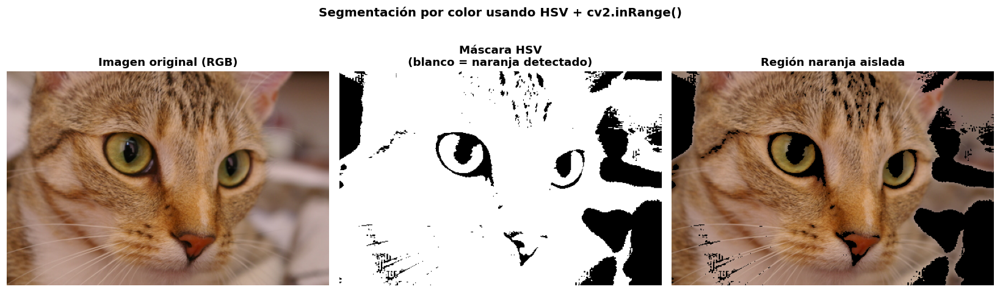

In [9]:
# ─── Segmentación por color en HSV ───────────────────────────────────────────

# Rango de Hue para el color naranja del gato:
# En OpenCV: naranja/marrón cálido ≈ Hue 5–25
lower_orange = np.array([4,  60, 80])    # [H_min, S_min, V_min]
upper_orange = np.array([25, 255, 255])  # [H_max, S_max, V_max]

# Crear máscara: píxeles dentro del rango → 255 (blanco)
#                píxeles fuera del rango  → 0   (negro)
mask = cv2.inRange(img_hsv, lower_orange, upper_orange)

# Aplicar máscara a la imagen original
# cv2.bitwise_and: mantiene el píxel si la máscara es 255, lo pone en 0 si es 0
img_segmentada = cv2.bitwise_and(img_bgr, img_bgr, mask=mask)
img_segmentada_rgb = cv2.cvtColor(img_segmentada, cv2.COLOR_BGR2RGB)

print(f'Total de píxeles:          {mask.size:,}')
print(f'Píxeles detectados (=255): {np.sum(mask == 255):,}  '
      f'({100 * np.sum(mask == 255) / mask.size:.1f}%)')

# Visualización
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(img_rgb)
axes[0].set_title('Imagen original (RGB)', fontweight='bold')

axes[1].imshow(mask, cmap='gray')
axes[1].set_title('Máscara HSV\n(blanco = naranja detectado)', fontweight='bold')

axes[2].imshow(img_segmentada_rgb)
axes[2].set_title('Región naranja aislada', fontweight='bold')

for ax in axes:
    ax.axis('off')

plt.suptitle('Segmentación por color usando HSV + cv2.inRange()', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### 4.3 ✏️ Actividad Guiada — Segmentar el café

La imagen `data.coffee()` tiene tonos marrones/rojizos intensos.  
Tu tarea: **detectar la zona marrón de la taza** usando el rango de Hue adecuado.

**Pista de rangos HSV en OpenCV:**
| Color | H_min | H_max | S_min recomendado |
|-------|-------|-------|--------------------|
| Rojo  | 0     | 10    | 50                |
| Naranja | 10  | 25    | 60                |
| Amarillo | 25 | 35   | 60                |
| Verde | 35    | 85    | 50                |
| Azul  | 100   | 130   | 50                |
| Marrón/café | 0 | 20 | 50               |

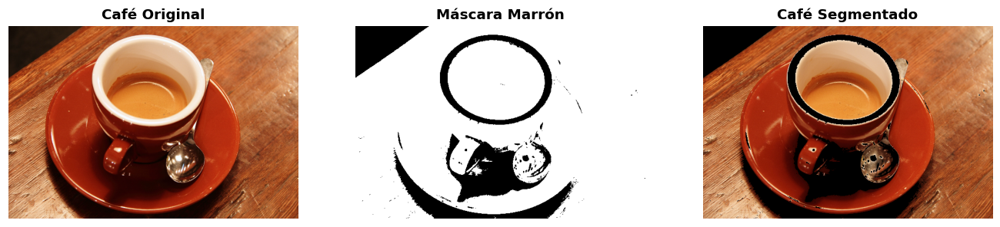

In [10]:
# TODO 4 — Segmentar el color marrón/café en data.coffee()

# Paso 1: convertir img_coffee a BGR
img_coffee_bgr = cv2.cvtColor(img_coffee, cv2.COLOR_RGB2BGR)

# Paso 2: convertir a HSV
img_coffee_hsv = cv2.cvtColor(img_coffee_bgr, cv2.COLOR_BGR2HSV)

# Paso 3: definir rango lower y upper para el color marrón/café (Hue entre 0 y 20)
lower_brown = np.array([0, 50, 50])
upper_brown = np.array([20, 255, 255])

# Paso 4: crear la máscara
mask_coffee = cv2.inRange(img_coffee_hsv, lower_brown, upper_brown)

# Paso 5: aplicar la máscara y mostrar resultados
coffee_segmentado = cv2.bitwise_and(img_coffee_bgr, img_coffee_bgr, mask=mask_coffee)
coffee_segmentado_rgb = cv2.cvtColor(coffee_segmentado, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img_coffee)
axes[0].set_title('Café Original', fontweight='bold')
axes[1].imshow(mask_coffee, cmap='gray')
axes[1].set_title('Máscara Marrón', fontweight='bold')
axes[2].imshow(coffee_segmentado_rgb)
axes[2].set_title('Café Segmentado', fontweight='bold')

for ax in axes:
    ax.axis('off')

plt.show()

---
## ⬜🔬 Paso 5 — Escala de Grises y Espacio LAB

### 5.1 Demostración: Cuatro formas de obtener escala de grises

Cuando convertimos a escala de grises, **perdemos la información de color pero ganamos eficiencia**.  
Existen varias fórmulas. La más usada es la *luminosidad perceptual* que le da más peso al verde.

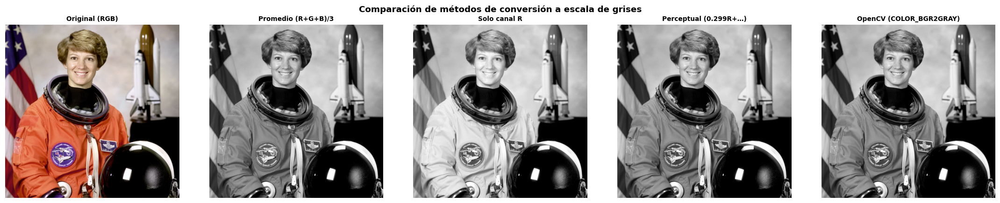


→ La conversión perceptual (OpenCV) preserva mejor el contraste visual percibido por el ojo humano.


In [11]:
# ─── Cuatro métodos para escala de grises ────────────────────────────────────
img = img_astronaut

# Método 1: Promedio simple de R, G, B
gray_promedio = img.mean(axis=2).astype(np.uint8)

# Método 2: Solo canal R
gray_solo_R = img[:, :, 0]

# Método 3: Luminosidad perceptual (BT.601 — pesa más G porque el ojo es más sensible al verde)
# Fórmula: 0.299*R + 0.587*G + 0.114*B
gray_perceptual = (0.299 * img[:, :, 0] +
                   0.587 * img[:, :, 1] +
                   0.114 * img[:, :, 2]).astype(np.uint8)

# Método 4: OpenCV (usa la fórmula perceptual internamente)
img_bgr = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
gray_cv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

# Visualización comparativa
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
items = [
    (img,             'Original (RGB)',          None),
    (gray_promedio,   'Promedio (R+G+B)/3',      'gray'),
    (gray_solo_R,     'Solo canal R',             'gray'),
    (gray_perceptual, 'Perceptual (0.299R+…)',    'gray'),
    (gray_cv,         'OpenCV (COLOR_BGR2GRAY)',  'gray'),
]
for ax, (imagen, titulo, cmap) in zip(axes, items):
    ax.imshow(imagen, cmap=cmap)
    ax.set_title(titulo, fontweight='bold', fontsize=9)
    if cmap == 'gray':
        ax.set_xlabel(f'media: {imagen.mean():.1f}')
    ax.axis('off')

plt.suptitle('Comparación de métodos de conversión a escala de grises', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print('\n→ La conversión perceptual (OpenCV) preserva mejor el contraste visual percibido por el ojo humano.')

### 5.2 Demostración: Espacio LAB — ¿Por qué es útil comparar colores?

En el espacio LAB, la distancia euclidiana entre dos colores se corresponde con la diferencia  
que percibe el ojo humano. Esto lo hace ideal para comparar colores y detección de cambios.

=== Canales LAB ===
L (Luminosidad): min=  0  max=255  media=121.8
a (Verde→Rojo):  min=114  max=190  media=141.6  (128=neutro)
b (Azul→Amr):    min= 76  max=190  media=140.0  (128=neutro)


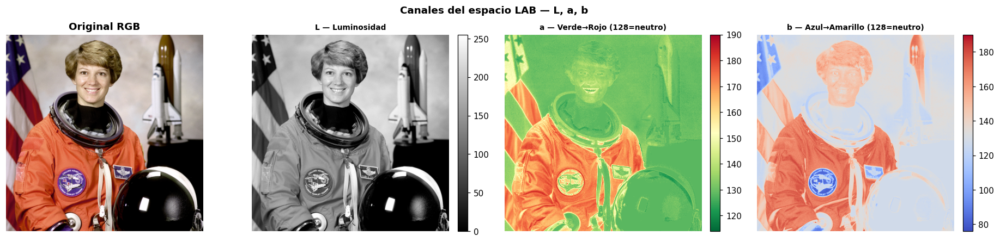


Píxel A: RGB=[187 176 169]  LAB=[185 131 133]
Píxel B: RGB=[232 219 221]  LAB=[226 133 129]
Distancia euclidiana en RGB: 81.10
Distancia euclidiana en LAB: 41.24 (más representativa perceptualmente)


In [12]:
# ─── Conversión a LAB y análisis de canales ───────────────────────────────────
img_bgr = cv2.cvtColor(img_astronaut, cv2.COLOR_RGB2BGR)
img_lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)

L_canal = img_lab[:, :, 0]   # Luminosidad: 0–255 (en OpenCV, normalizado de 0–100)
a_canal = img_lab[:, :, 1]   # Verde → Rojo: 0–255 (128 = neutro)
b_canal = img_lab[:, :, 2]   # Azul → Amarillo: 0–255 (128 = neutro)

print('=== Canales LAB ===')
print(f'L (Luminosidad): min={L_canal.min():3d}  max={L_canal.max():3d}  media={L_canal.mean():.1f}')
print(f'a (Verde→Rojo):  min={a_canal.min():3d}  max={a_canal.max():3d}  media={a_canal.mean():.1f}  (128=neutro)')
print(f'b (Azul→Amr):    min={b_canal.min():3d}  max={b_canal.max():3d}  media={b_canal.mean():.1f}  (128=neutro)')

# Comparación LAB vs HSV vs RGB para visualización de canales
fig, axes = plt.subplots(1, 4, figsize=(17, 4))

axes[0].imshow(img_astronaut)
axes[0].set_title('Original RGB', fontweight='bold')

for ax, (canal, titulo, cmap) in zip(axes[1:], [
    (L_canal, 'L — Luminosidad', 'gray'),
    (a_canal, 'a — Verde→Rojo (128=neutro)', 'RdYlGn_r'),
    (b_canal, 'b — Azul→Amarillo (128=neutro)', 'coolwarm'),
]):
    im = ax.imshow(canal, cmap=cmap)
    ax.set_title(titulo, fontweight='bold', fontsize=9)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

for ax in axes:
    ax.axis('off')

plt.suptitle('Canales del espacio LAB — L, a, b', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# Demostración de distancia de color
# Comparar el mismo píxel en RGB vs LAB
px1 = img_astronaut[100, 100]   # un píxel
px2 = img_astronaut[200, 300]   # otro píxel

lab1 = img_lab[100, 100].astype(float)
lab2 = img_lab[200, 300].astype(float)

dist_rgb = np.linalg.norm(px1.astype(float) - px2.astype(float))
dist_lab = np.linalg.norm(lab1 - lab2)

print(f'\nPíxel A: RGB={px1}  LAB={img_lab[100,100]}')
print(f'Píxel B: RGB={px2}  LAB={img_lab[200,300]}')
print(f'Distancia euclidiana en RGB: {dist_rgb:.2f}')
print(f'Distancia euclidiana en LAB: {dist_lab:.2f} (más representativa perceptualmente)')

---
## 🖨️ Paso 6 — Conversión CMYK Manual

### 6.1 Demostración: RGB → CMYK con numpy

OpenCV no tiene soporte nativo para CMYK.  
Usamos las fórmulas matemáticas directamente con numpy:

```
R' = R / 255  (normalizar a [0, 1])
K  = 1 - max(R', G', B')        → canal negro
C  = (1 - R' - K) / (1 - K)    → cian
M  = (1 - G' - K) / (1 - K)    → magenta
Y  = (1 - B' - K) / (1 - K)    → amarillo
```

=== Canales CMYK (valores en [0, 1]) ===
  C (Cian): min=0.000  max=1.000  media=0.019
  M (Magenta): min=0.000  max=1.000  media=0.266
  Y (Yellow): min=0.000  max=1.000  media=0.318
  K (Negro): min=0.000  max=1.000  media=0.439


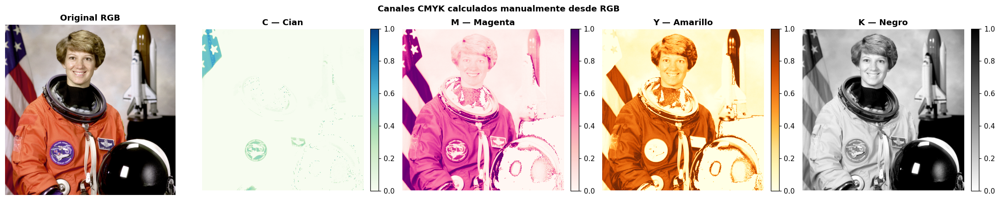

In [13]:
# ─── Conversión RGB → CMYK con numpy ──────────────────────────────────────────
def rgb_to_cmyk(img_rgb):
    """Convierte una imagen RGB (uint8) a 4 canales CMYK normalizados [0, 1]."""
    img_f = img_rgb.astype(np.float32) / 255.0   # normalizar a [0, 1]
    
    # Canal K (negro): inverso del máximo de los tres canales
    K = 1.0 - np.max(img_f, axis=2)              # shape: (H, W)
    
    # Evitar división por cero en píxeles negros puros (K=1)
    denom = (1.0 - K) + 1e-10
    
    C = (1.0 - img_f[:, :, 0] - K) / denom      # cian
    M = (1.0 - img_f[:, :, 1] - K) / denom      # magenta
    Y = (1.0 - img_f[:, :, 2] - K) / denom      # amarillo
    
    return np.clip(C, 0, 1), np.clip(M, 0, 1), np.clip(Y, 0, 1), np.clip(K, 0, 1)

# Aplicar conversión
C, M, Y, K = rgb_to_cmyk(img_astronaut)

print('=== Canales CMYK (valores en [0, 1]) ===')
for nombre, canal in [('C (Cian)',   C), ('M (Magenta)', M),
                       ('Y (Yellow)', Y), ('K (Negro)',   K)]:
    print(f'  {nombre}: min={canal.min():.3f}  max={canal.max():.3f}  media={canal.mean():.3f}')

# Visualización de los 4 canales
fig, axes = plt.subplots(1, 5, figsize=(20, 4))

axes[0].imshow(img_astronaut)
axes[0].set_title('Original RGB', fontweight='bold')

config_cmyk = [
    (C, 'C — Cian',    'GnBu'),
    (M, 'M — Magenta', 'RdPu'),
    (Y, 'Y — Amarillo','YlOrBr'),
    (K, 'K — Negro',   'gray_r'),
]
for ax, (canal, titulo, cmap) in zip(axes[1:], config_cmyk):
    im = ax.imshow(canal, cmap=cmap, vmin=0, vmax=1)
    ax.set_title(titulo, fontweight='bold')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

for ax in axes:
    ax.axis('off')

plt.suptitle('Canales CMYK calculados manualmente desde RGB', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 💾 Paso 7 — Formatos de Imagen: JPEG vs PNG vs BMP

### 7.1 Demostración: Impacto del formato en calidad y tamaño

Vamos a guardar la misma imagen en 4 formatos y comparar el tamaño del archivo  
y la calidad resultante (usando PSNR — Peak Signal-to-Noise Ratio).

Formato                   Archivo                    Tamaño (KB)  Factor compresión
----------------------------------------------------------------------------------
JPEG (calidad 95)         astronauta_q95.jpg               97.0               7.9x
JPEG (calidad 40)         astronauta_q40.jpg               23.8              32.2x
PNG (sin pérdida)         astronauta.png                  430.1               1.8x
BMP (crudo)               astronauta.bmp                  768.1               1.0x

PSNR JPEG q=95 vs original: 38.28 dB
PSNR JPEG q=40 vs original: 31.40 dB


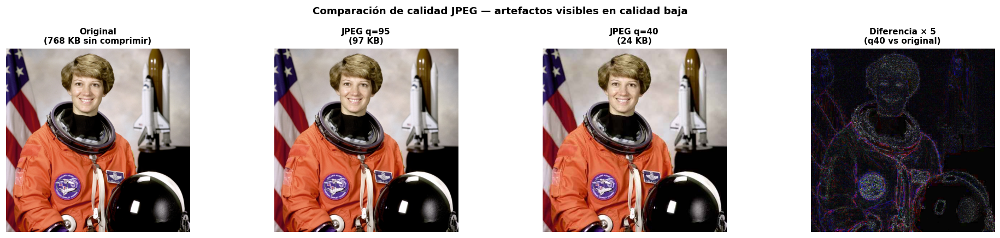

In [14]:
# ─── Comparación de formatos ──────────────────────────────────────────────────
img_pil = Image.fromarray(img_astronaut)   # convertir a objeto Pillow

# Guardar en distintos formatos
formatos = {
    'JPEG (calidad 95)': ('astronauta_q95.jpg',  {'quality': 95}),
    'JPEG (calidad 40)': ('astronauta_q40.jpg',  {'quality': 40}),
    'PNG (sin pérdida)': ('astronauta.png',       {}),
    'BMP (crudo)':       ('astronauta.bmp',       {}),
}

for nombre, (archivo, kwargs) in formatos.items():
    img_pil.save(archivo, **kwargs)

# Calcular tamaños y mostrar comparativa
print(f'{"Formato":<25} {"Archivo":<25} {"Tamaño (KB)":>12} {"Factor compresión":>18}')
print('-' * 82)

tamano_bmp = os.path.getsize('astronauta.bmp') / 1024
for nombre, (archivo, _) in formatos.items():
    kb = os.path.getsize(archivo) / 1024
    factor = tamano_bmp / kb
    print(f'{nombre:<25} {archivo:<25} {kb:>11.1f} {factor:>17.1f}x')

# Visualización: comparar calidad JPEG 95 vs 40
img_q95 = np.array(Image.open('astronauta_q95.jpg'))
img_q40 = np.array(Image.open('astronauta_q40.jpg'))

# PSNR: mayor es mejor. > 40dB: excelente, 30–40: bueno, < 30: pérdida notable
def psnr(original, comparado):
    """Peak Signal-to-Noise Ratio — cuantifica la pérdida de calidad."""
    mse = np.mean((original.astype(float) - comparado.astype(float)) ** 2)
    if mse == 0:
        return float('inf')
    return 20 * np.log10(255.0 / np.sqrt(mse))

print(f'\nPSNR JPEG q=95 vs original: {psnr(img_astronaut, img_q95):.2f} dB')
print(f'PSNR JPEG q=40 vs original: {psnr(img_astronaut, img_q40):.2f} dB')

# Mostrar diferencia amplificada
diff = np.abs(img_astronaut.astype(float) - img_q40.astype(float)).astype(np.uint8)
diff_amplificado = np.clip(diff * 5, 0, 255).astype(np.uint8)  # amplificar para visualizar

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
items = [
    (img_astronaut,     f'Original\n({tamano_bmp:.0f} KB sin comprimir)'),
    (img_q95,           f'JPEG q=95\n({os.path.getsize("astronauta_q95.jpg")/1024:.0f} KB)'),
    (img_q40,           f'JPEG q=40\n({os.path.getsize("astronauta_q40.jpg")/1024:.0f} KB)'),
    (diff_amplificado,  'Diferencia × 5\n(q40 vs original)'),
]
for ax, (imagen, titulo) in zip(axes, items):
    ax.imshow(imagen)
    ax.set_title(titulo, fontweight='bold', fontsize=10)
    ax.axis('off')

plt.suptitle('Comparación de calidad JPEG — artefactos visibles en calidad baja', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

### 7.2 ✏️ Actividad Guiada — Explorar calidades JPEG

Guardá la imagen del gato (`img_cat`) con **5 calidades JPEG distintas** (10, 30, 50, 70, 95)  
y graficá la relación entre calidad JPEG y tamaño del archivo en un gráfico de línea.

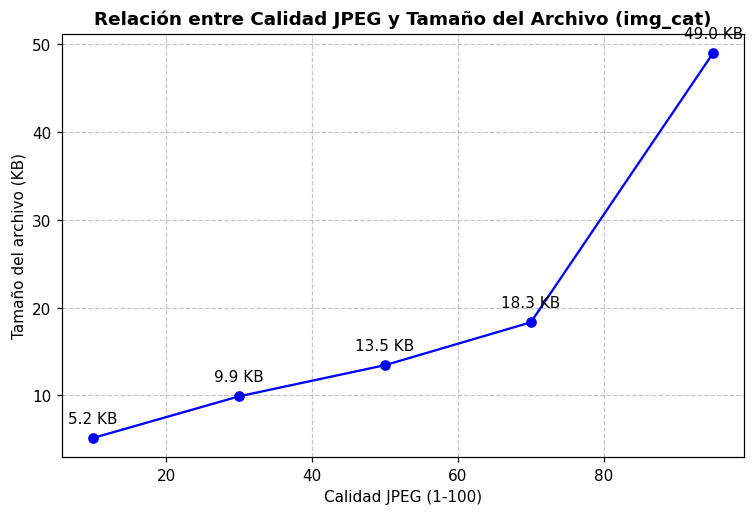

In [15]:
# TODO 7 — Guardar img_cat con 5 calidades y graficar tamaño vs calidad
img_pil_cat = Image.fromarray(img_cat)
calidades = [10, 30, 50, 70, 95]
tamanos_kb = []

# Guardar y calcular tamaños
for q in calidades:
    filename = f'gato_q{q}.jpg'
    img_pil_cat.save(filename, quality=q)
    tamano = os.path.getsize(filename) / 1024
    tamanos_kb.append(tamano)

# Graficar
plt.figure(figsize=(8, 5))
plt.plot(calidades, tamanos_kb, marker='o', linestyle='-', color='b')
plt.title('Relación entre Calidad JPEG y Tamaño del Archivo (img_cat)', fontweight='bold')
plt.xlabel('Calidad JPEG (1-100)')
plt.ylabel('Tamaño del archivo (KB)')
plt.grid(True, linestyle='--', alpha=0.7)

# Agregar etiquetas de valor en cada punto
for q, t in zip(calidades, tamanos_kb):
    plt.annotate(f"{t:.1f} KB", (q, t), textcoords="offset points", xytext=(0,10), ha='center')

plt.show()

---
## 🏆 Actividad Autónoma — Pipeline Completo de Análisis

> **Para entregar:** Completá este análisis como actividad semanal.  
> Este notebook cuenta para la condición de regularidad (≥ 60% de entregas).

### Consigna

Elegí **UNA** de las tres imágenes disponibles:

```python
img_elegida = data.astronaut()   # clásica, colores variados
img_elegida = data.coffee()      # tonos cálidos
img_elegida = data.chelsea()     # gato naranja, ideal para segmentación
```

Tu análisis debe incluir los siguientes puntos **(cada ítem debe mostrarse ejecutado)**:

| Ítem | Descripción |
|------|-------------|
| **A** | Análisis matricial: shape, dtype, min, max, media por canal RGB |
| **B** | Visualización de los 3 canales RGB con colormaps individuales |
| **C** | Modificar directamente 3 regiones de píxeles (tipos: franja, ROI, patrón) |
| **D** | Conversión a HSV y visualización de los 3 canales |
| **E** | Segmentación de un color de tu elección usando `cv2.inRange()` |
| **F** | Conversión a escala de grises y a LAB — mostrar canales de ambos |
| **G** | Guardar en JPEG (2 calidades) y PNG — tabla comparativa de tamaños y PSNR |
| **H** | Conclusiones: al menos 3 observaciones fundamentadas sobre lo analizado |

In [18]:
# ─── ZONA DE TRABAJO — ACTIVIDAD AUTÓNOMA ────────────────────────────────────

# Paso 0: elegí tu imagen
img_elegida = data.astronaut()
# img_elegida = data.coffee()
# img_elegida = data.chelsea()


In [19]:
# A — Análisis matricial
R, G, B = img_elegida[:,:,0], img_elegida[:,:,1], img_elegida[:,:,2]

print("=== Análisis Matricial ===")
print(f"Shape: {img_elegida.shape}")
print(f"Data type: {img_elegida.dtype}")
print(f"Min: {img_elegida.min()} | Max: {img_elegida.max()}")
print(f"Media Canal R: {R.mean():.2f}")
print(f"Media Canal G: {G.mean():.2f}")
print(f"Media Canal B: {B.mean():.2f}")

=== Análisis Matricial ===
Shape: (512, 512, 3)
Data type: uint8
Min: 0 | Max: 255
Media Canal R: 141.56
Media Canal G: 105.76
Media Canal B: 96.48


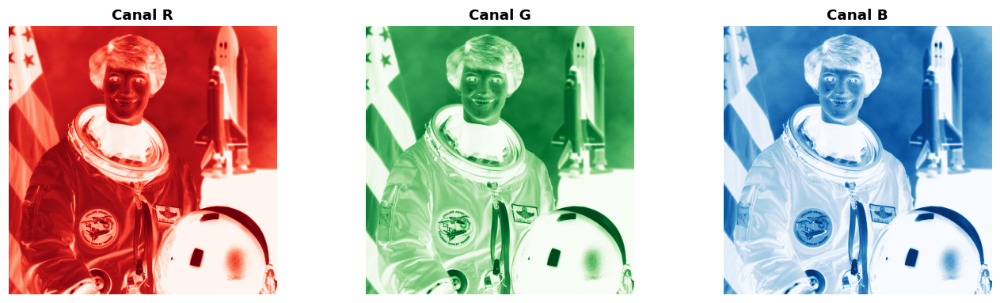

In [20]:
# B — Visualización de canales RGB
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(R, cmap='Reds'); axes[0].set_title('Canal R', fontweight='bold'); axes[0].axis('off')
axes[1].imshow(G, cmap='Greens'); axes[1].set_title('Canal G', fontweight='bold'); axes[1].axis('off')
axes[2].imshow(B, cmap='Blues'); axes[2].set_title('Canal B', fontweight='bold'); axes[2].axis('off')
plt.show()

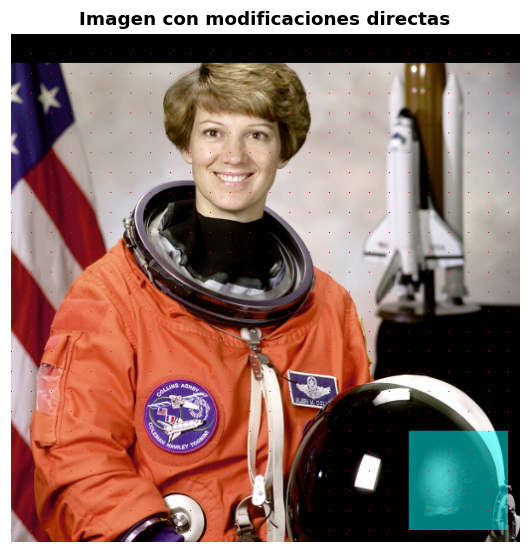

In [21]:
# C — Modificación directa de píxeles (3 tipos)
img_mod = img_elegida.copy()

# 1. Franja negra horizontal arriba
img_mod[0:30, :] = [0, 0, 0]

# 2. ROI: Cuadro cian semi-transparente en la esquina inferior derecha
roi = img_mod[400:500, 400:500]
img_mod[400:500, 400:500] = (roi * 0.5 + np.array([0, 255, 255]) * 0.5).astype(np.uint8)

# 3. Patrón: Cuadrícula punteada roja simple
img_mod[::20, ::20] = [255, 0, 0]

plt.figure(figsize=(6,6))
plt.imshow(img_mod)
plt.title("Imagen con modificaciones directas", fontweight='bold')
plt.axis('off')
plt.show()

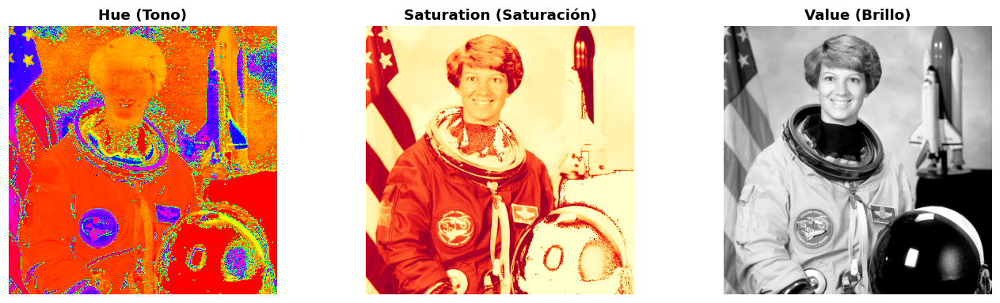

In [22]:
# D — Conversión a HSV y visualización
img_bgr = cv2.cvtColor(img_elegida, cv2.COLOR_RGB2BGR)
img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(img_hsv[:,:,0], cmap='hsv'); axes[0].set_title('Hue (Tono)', fontweight='bold'); axes[0].axis('off')
axes[1].imshow(img_hsv[:,:,1], cmap='YlOrRd'); axes[1].set_title('Saturation (Saturación)', fontweight='bold'); axes[1].axis('off')
axes[2].imshow(img_hsv[:,:,2], cmap='gray'); axes[2].set_title('Value (Brillo)', fontweight='bold'); axes[2].axis('off')
plt.show()

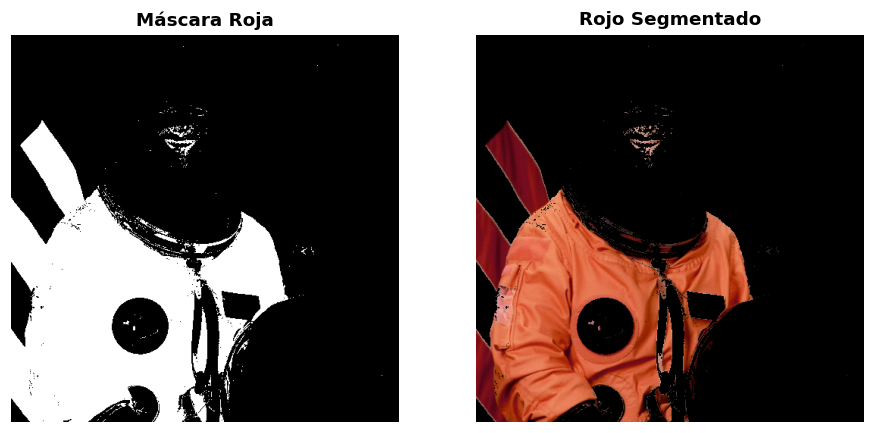

In [23]:
# E — Segmentación por color (Vamos a detectar los parches rojos y la bandera en el traje)
# El rojo en OpenCV HSV se divide en dos rangos (0-10 y 170-180)
lower_red1 = np.array([0, 70, 50])
upper_red1 = np.array([10, 255, 255])
lower_red2 = np.array([170, 70, 50])
upper_red2 = np.array([180, 255, 255])

mask1 = cv2.inRange(img_hsv, lower_red1, upper_red1)
mask2 = cv2.inRange(img_hsv, lower_red2, upper_red2)
mask_red = cv2.bitwise_or(mask1, mask2)

segmentado = cv2.bitwise_and(img_bgr, img_bgr, mask=mask_red)
segmentado_rgb = cv2.cvtColor(segmentado, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(mask_red, cmap='gray'); axes[0].set_title('Máscara Roja', fontweight='bold'); axes[0].axis('off')
axes[1].imshow(segmentado_rgb); axes[1].set_title('Rojo Segmentado', fontweight='bold'); axes[1].axis('off')
plt.show()

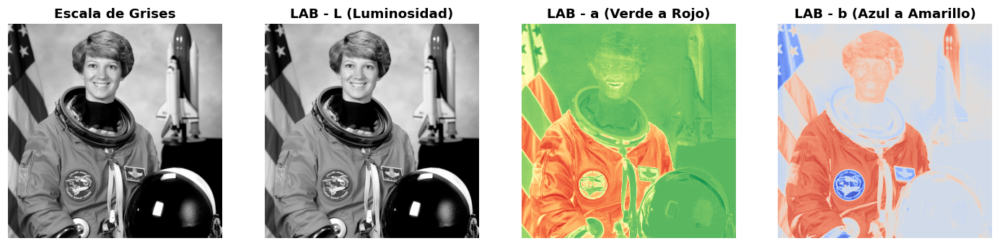

In [24]:
# F — Escala de grises y LAB
gray_img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
lab_img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(gray_img, cmap='gray'); axes[0].set_title('Escala de Grises', fontweight='bold'); axes[0].axis('off')
axes[1].imshow(lab_img[:,:,0], cmap='gray'); axes[1].set_title('LAB - L (Luminosidad)', fontweight='bold'); axes[1].axis('off')
axes[2].imshow(lab_img[:,:,1], cmap='RdYlGn_r'); axes[2].set_title('LAB - a (Verde a Rojo)', fontweight='bold'); axes[2].axis('off')
axes[3].imshow(lab_img[:,:,2], cmap='coolwarm'); axes[3].set_title('LAB - b (Azul a Amarillo)', fontweight='bold'); axes[3].axis('off')
plt.show()

In [25]:
# G — Comparación de formatos (JPEG y PNG)
img_pil_auto = Image.fromarray(img_elegida)
img_pil_auto.save('astronaut_q95.jpg', quality=95)
img_pil_auto.save('astronaut_q30.jpg', quality=30)
img_pil_auto.save('astronaut.png')

kb_q95 = os.path.getsize('astronaut_q95.jpg') / 1024
kb_q30 = os.path.getsize('astronaut_q30.jpg') / 1024
kb_png = os.path.getsize('astronaut.png') / 1024

def calc_psnr(orig, comp):
    mse = np.mean((orig.astype(float) - comp.astype(float))**2)
    if mse == 0: return float('inf')
    return 20 * np.log10(255.0 / np.sqrt(mse))

psnr_q95 = calc_psnr(img_elegida, np.array(Image.open('astronaut_q95.jpg')))
psnr_q30 = calc_psnr(img_elegida, np.array(Image.open('astronaut_q30.jpg')))
psnr_png = calc_psnr(img_elegida, np.array(Image.open('astronaut.png'))) 

print("=== Comparativa de Archivos ===")
print(f"PNG (sin pérdida): {kb_png:.1f} KB | PSNR: {psnr_png}")
print(f"JPEG (q=95): {kb_q95:.1f} KB | PSNR: {psnr_q95:.2f} dB")
print(f"JPEG (q=30): {kb_q30:.1f} KB | PSNR: {psnr_q30:.2f} dB")

=== Comparativa de Archivos ===
PNG (sin pérdida): 430.1 KB | PSNR: inf
JPEG (q=95): 97.0 KB | PSNR: 38.28 dB
JPEG (q=30): 20.4 KB | PSNR: 30.54 dB


### H — Conclusiones

**Conclusión 1:** *(sobre canales RGB — ¿qué canal domina y por qué?)*  
En la imagen del astronauta, los canales Rojo (R) y Verde (G) tienen medias más altas. Esto tiene sentido porque hay una fuerte presencia del traje naranja/rojizo y tonos de piel humana, los cuales requieren una mezcla alta de rojo y verde, mientras que el azul queda más relegado a detalles específicos o sombras.

**Conclusión 2:** *(sobre espacios de color — ¿cuándo preferirías HSV sobre RGB?)*  
Preferiría usar el espacio HSV siempre que necesite aislar o detectar un objeto por su color (como hicimos con los parches rojos de la bandera). En RGB, el color varía en sus 3 canales si cambia la sombra o la luz; en cambio, en HSV el color base (Hue) se mantiene constante sin importar los cambios de iluminación (Value).

**Conclusión 3:** *(sobre formatos — ¿qué formato usarías para cada caso de uso?)*  
Usaría PNG cuando necesite calidad perfecta sin pérdida (PSNR infinito) como en análisis científico de imágenes o gráficos con transparencias, asumiendo el mayor tamaño del archivo. Usaría JPEG (con calidad alta, ej. 95) para fotografías generales o desarrollo, ya que reduce drásticamente el tamaño del archivo sin que el ojo humano note una diferencia sustancial (PSNR alto).

---

## 📋 Resumen de lo Practicado en esta Clase

| Concepto | Lo que practicamos |
|----------|--------------------|
| **Imagen = array numpy** | `img.shape`, `img.dtype`, `img[f, c]`, `img[f, c, canal]` |
| **Canales RGB** | Separar con `[:,:,0]`, visualizar con cmaps, recombinar con `np.stack` |
| **Píxeles directos** | Leer, modificar franjas, ROIs y patrones con indexing de numpy |
| **Espacio HSV** | `cv2.COLOR_BGR2HSV`, visualización de H/S/V, modificar brillo |
| **Segmentación** | `cv2.inRange()`, `cv2.bitwise_and()` para aislar colores |
| **Escala de grises** | 4 métodos comparados, fórmula perceptual BT.601 |
| **Espacio LAB** | `cv2.COLOR_BGR2LAB`, canales L/a/b, distancia perceptual |
| **CMYK** | Conversión manual con numpy, visualización de 4 canales |
| **Formatos** | JPEG con distintas calidades, PNG sin pérdida, cálculo de PSNR |

### 📚 Para la próxima clase

La **Clase 5** aborda la mejora y ajuste de imágenes:  
transformaciones geométricas (rotación, escalado), brillo, contraste y filtros básicos.  
**Entrega del Notebook Obligatorio N° 2** en la Clase 4 (esta actividad).

---
*Politécnico Malvinas Argentinas | Tecnicatura en Cs de Datos e IA | Procesamiento de Imágenes 2026*